<a href="https://colab.research.google.com/github/elisabethcoller/CDD-Noise-Filtering-Algorithm/blob/main/microcontroller_algorithm/my_algorithm_11_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Time sync data points

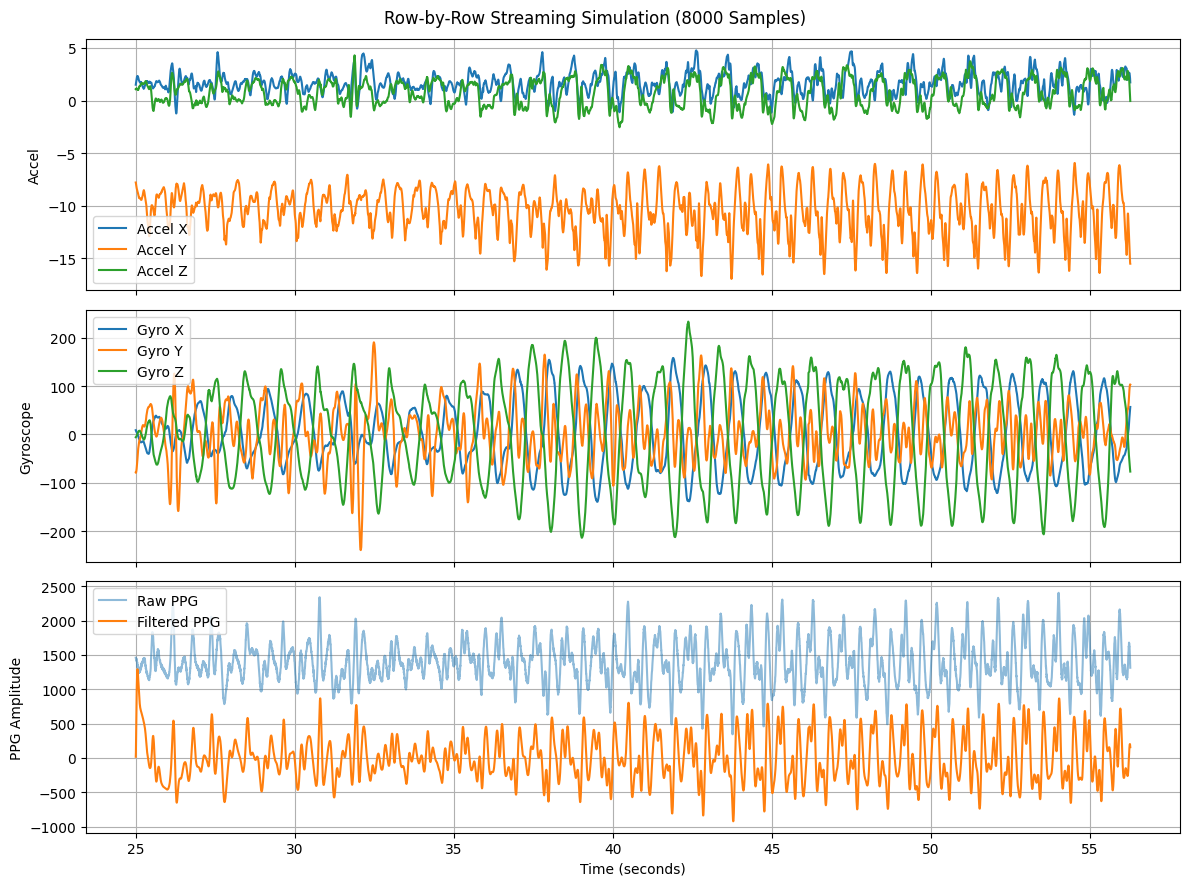

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter, lfilter_zi

# =====================================================================
# 1. CONFIGURATION
# =====================================================================
CONFIG = {
    "file_path": "s3.csv",
    "sampling_rate_hz": 256.0,
    "num_test_samples": 8000,  # None = process entire CSV
    "ppg_filter": {
        "lowcut": 0.4,
        "highcut": 10.0,
        "order": 2
    },
    "column_mapping": {
        "time": "sample_times_for_all_signals_apart_from_ecg",
        "ppg": "wrist_ppg",
        "gyro_x": "wrist_gyro_x",
        "gyro_y": "wrist_gyro_y",
        "gyro_z": "wrist_gyro_z",
        "accel_x": "wrist_low_noise_accelerometer_x",
        "accel_y": "wrist_low_noise_accelerometer_y",
        "accel_z": "wrist_low_noise_accelerometer_z"
    }
}

# =====================================================================
# 2. LOAD DATA
# =====================================================================
path = CONFIG["file_path"]

if not os.path.exists(path):
    raise FileNotFoundError(f"File '{path}' not found.")

df = pd.read_csv(path)
cols = CONFIG["column_mapping"]

# Limit number of incoming samples
if CONFIG["num_test_samples"] is not None:
    df = df.iloc[:CONFIG["num_test_samples"]].copy()

times = df[cols["time"]].to_numpy()
raw_ppg = df[cols["ppg"]].to_numpy()

accel = df[
    [cols["accel_x"], cols["accel_y"], cols["accel_z"]]
].to_numpy()

gyro = df[
    [cols["gyro_x"], cols["gyro_y"], cols["gyro_z"]]
].to_numpy()

num_samples = len(df)

# =====================================================================
# 3. FILTER SETUP
# =====================================================================
fs = CONFIG["sampling_rate_hz"]

low = CONFIG["ppg_filter"]["lowcut"]
high = CONFIG["ppg_filter"]["highcut"]
order = CONFIG["ppg_filter"]["order"]

b, a = butter(
    order,
    [low / (fs / 2), high / (fs / 2)],
    btype="band"
)

# Initialize filter state
zi_state = lfilter_zi(b, a) * 0

# =====================================================================
# 4. STREAMING PROCESSING: ONE ROW AT A TIME
# =====================================================================
time_data = []
raw_ppg_all = []
clean_ppg_all = []

ax_all, ay_all, az_all = [], [], []
gx_all, gy_all, gz_all = [], [], []

for sample_idx in range(num_samples):

    # ---------------------------------------------------------------
    # SIMULATE ONE INCOMING SENSOR ROW
    # ---------------------------------------------------------------
    incoming_time = times[sample_idx]
    incoming_ppg = raw_ppg[sample_idx]

    incoming_accel = accel[sample_idx]
    incoming_gyro = gyro[sample_idx]

    # ---------------------------------------------------------------
    # PROCESS ONE PPG SAMPLE
    # ---------------------------------------------------------------
    clean_sample, zi_state = lfilter(
        b,
        a,
        [incoming_ppg],
        zi=zi_state
    )

    # Extract scalar filtered output
    clean_sample = clean_sample[0]

    # ---------------------------------------------------------------
    # STORE OUTPUTS
    # ---------------------------------------------------------------
    time_data.append(incoming_time)

    raw_ppg_all.append(incoming_ppg)
    clean_ppg_all.append(clean_sample)

    ax_all.append(incoming_accel[0])
    ay_all.append(incoming_accel[1])
    az_all.append(incoming_accel[2])

    gx_all.append(incoming_gyro[0])
    gy_all.append(incoming_gyro[1])
    gz_all.append(incoming_gyro[2])

    # Optional progress indicator
    # if sample_idx % 1000 == 0:
    #     print(f"Processed {sample_idx} samples")

# =====================================================================
# 5. PLOTTING
# =====================================================================
fig, (ax_accel, ax_gyro, ax_ppg) = plt.subplots(
    3, 1, figsize=(12, 9), sharex=True
)

fig.suptitle(
    f"Row-by-Row Streaming Simulation ({num_samples} Samples)"
)

# Accelerometer
ax_accel.plot(time_data, ax_all, label="Accel X")
ax_accel.plot(time_data, ay_all, label="Accel Y")
ax_accel.plot(time_data, az_all, label="Accel Z")

ax_accel.set_ylabel("Accel")
ax_accel.legend()
ax_accel.grid(True)

# Gyroscope
ax_gyro.plot(time_data, gx_all, label="Gyro X")
ax_gyro.plot(time_data, gy_all, label="Gyro Y")
ax_gyro.plot(time_data, gz_all, label="Gyro Z")

ax_gyro.set_ylabel("Gyroscope")
ax_gyro.legend()
ax_gyro.grid(True)

# PPG
ax_ppg.plot(time_data, raw_ppg_all, label="Raw PPG", alpha=0.5)
ax_ppg.plot(time_data, clean_ppg_all, label="Filtered PPG")

ax_ppg.set_ylabel("PPG Amplitude")
ax_ppg.set_xlabel("Time (seconds)")
ax_ppg.legend()
ax_ppg.grid(True)

plt.tight_layout()
plt.show()


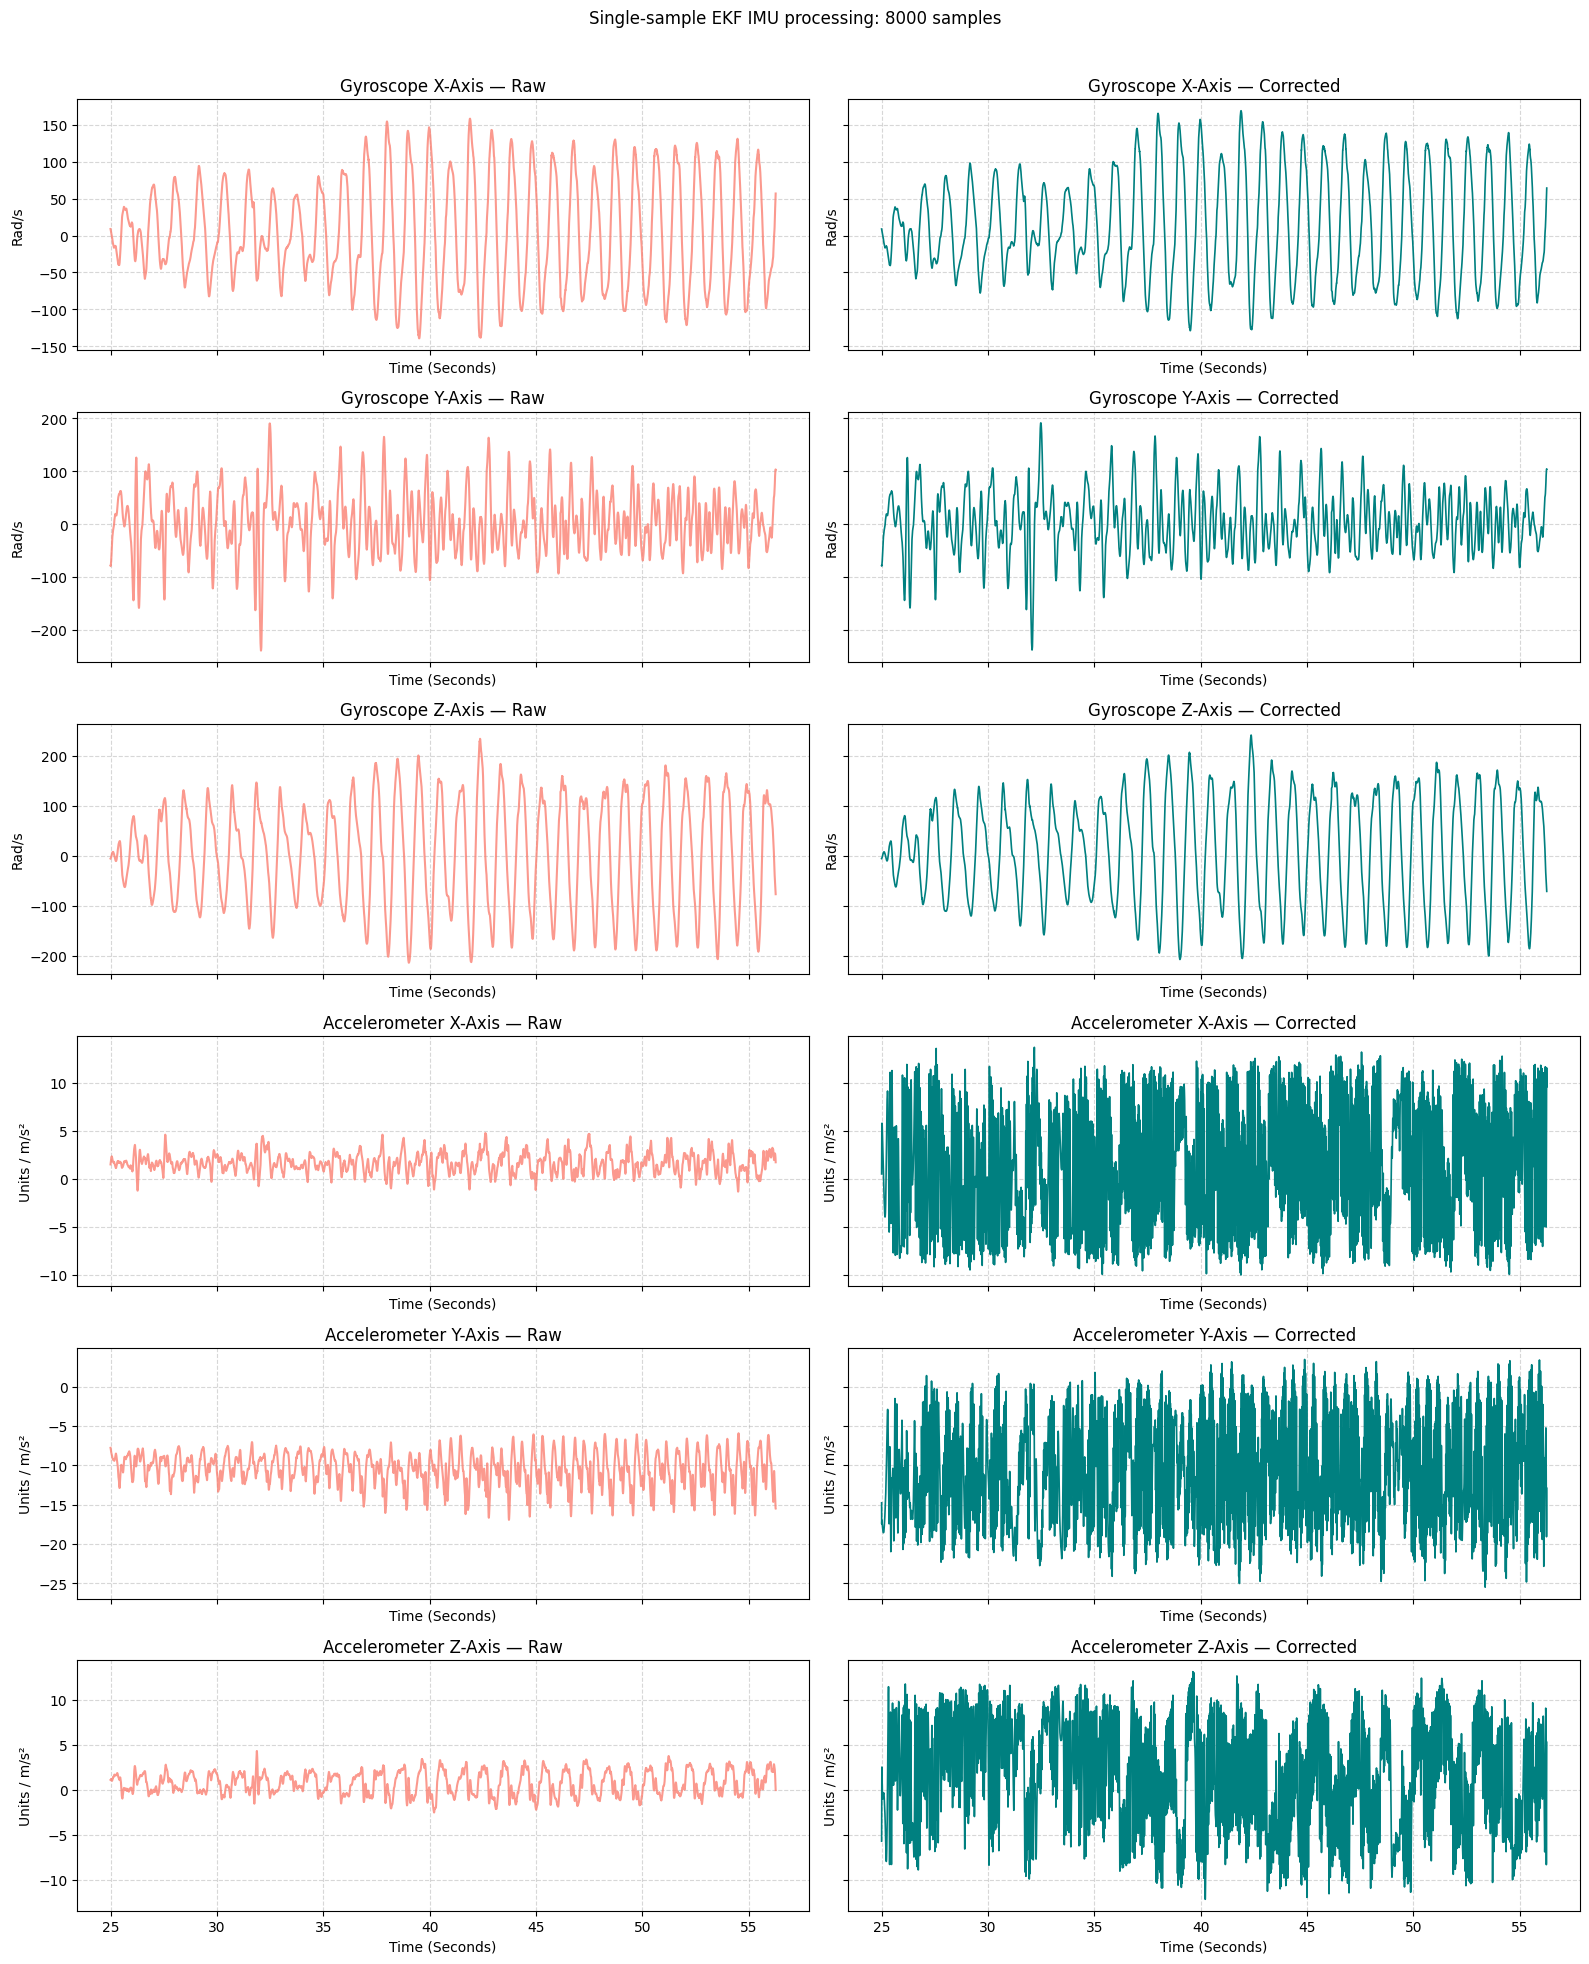

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Change run parameters here.
SETTINGS = {
    "file_path": "s3.csv",
    "num_test_samples": 8000,  # Set to None to process the entire file.
    "sampling_rate_hz": 256.0,  # Used if the time column cannot determine dt.
    "time_column": "sample_times_for_all_signals_apart_from_ecg",
    "gyro_columns": ["wrist_gyro_x", "wrist_gyro_y", "wrist_gyro_z"],
    "accel_columns": [
        "wrist_wide_range_accelerometer_x",
        "wrist_wide_range_accelerometer_y",
        "wrist_wide_range_accelerometer_z",
    ],
    "gravity_magnitude": 9.81,
    # Noise parameters (tune for your sensor and units).
    "accelerometer_noise": 0.02,
    "gyroscope_noise": 1.0e-5,
    "gyroscope_drift_noise": 1.0e-8,
    "linear_acceleration_noise": 0.1,
    "linear_acceleration_decay": 0.5,
    "initial_orientation_wxyz": [1.0, 0.0, 0.0, 0.0],
    "initial_gyro_bias": [0.0, 0.0, 0.0],
}


def rot_matrix_from_quaternion(q):
    """Compute a rotation matrix from quaternion [w, x, y, z]."""
    w, x, y, z = q
    return np.array([
        [1 - 2 * (y**2 + z**2), 2 * (x * y - z * w), 2 * (x * z + y * w)],
        [2 * (x * y + z * w), 1 - 2 * (x**2 + z**2), 2 * (y * z - x * w)],
        [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x**2 + y**2)],
    ])


def quaternion_multiply(q1, q2):
    """Hamilton product for quaternions stored as [w, x, y, z]."""
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2
    return np.array([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2,
    ])


def quaternion_from_rotation_vector(rotation_vector):
    """Convert a 3D rotation vector in radians to [w, x, y, z]."""
    angle = np.linalg.norm(rotation_vector)
    if angle < 1e-12:
        return np.array([1.0, 0.0, 0.0, 0.0])
    return np.r_[np.cos(angle / 2),
                 rotation_vector / angle * np.sin(angle / 2)]


def run_csv_imu_fusion(settings=SETTINGS):
    df = pd.read_csv(settings["file_path"])
    time_col = settings["time_column"]
    gyro_cols = settings["gyro_columns"]
    accel_cols = settings["accel_columns"]

    # Select sample count. Every iteration below processes exactly one row.
    requested_samples = settings["num_test_samples"]
    if requested_samples is not None:
        if requested_samples <= 0:
            raise ValueError("num_test_samples must be greater than zero or None")
        df = df.iloc[:int(requested_samples)].copy()

    t = df[time_col].to_numpy(dtype=float)
    gyro_raw = df[gyro_cols].to_numpy(dtype=float)
    accel_raw = df[accel_cols].to_numpy(dtype=float)
    num_samples = len(df)

    if num_samples == 0:
        raise ValueError("The selected file contains no samples")

    # Determine fallback dt from the timestamps or configured sampling rate.
    fallback_dt = 1.0 / float(settings["sampling_rate_hz"])
    if fallback_dt <= 0:
        raise ValueError("sampling_rate_hz must be greater than zero")
    time_diffs = np.diff(t) if num_samples > 1 else np.array([])
    valid_diffs = time_diffs[np.isfinite(time_diffs) & (time_diffs > 0)]
    default_dt = float(np.median(valid_diffs)) if len(valid_diffs) else fallback_dt

    # Persistent states: these remain in memory and update one sample at a time.
    g_global = np.array([0.0, 0.0, float(settings["gravity_magnitude"])])
    q_est = np.asarray(settings["initial_orientation_wxyz"], dtype=float).copy()
    q_norm = np.linalg.norm(q_est)
    if q_norm == 0:
        raise ValueError("initial_orientation_wxyz cannot be a zero quaternion")
    q_est /= q_norm

    bias_est = np.asarray(settings["initial_gyro_bias"], dtype=float).copy()
    linear_accel_est = np.zeros(3)
    P = np.diag([0.1] * 3 + [0.01] * 3 + [1.0] * 3)

    accel_noise = float(settings["accelerometer_noise"])
    gyro_noise = float(settings["gyroscope_noise"])
    gyro_drift_noise = float(settings["gyroscope_drift_noise"])
    lin_accel_noise = float(settings["linear_acceleration_noise"])
    lin_accel_decay = float(settings["linear_acceleration_decay"])

    # Output histories are for plotting/analysis; filter states are updated
    # sequentially, one incoming data row per iteration.
    gyro_corrected = np.zeros_like(gyro_raw)
    dynamic_accel = np.zeros_like(accel_raw)
    gravity_estimated = np.zeros_like(accel_raw)
    gyro_bias_history = np.zeros_like(gyro_raw)
    orientation_history = np.zeros((num_samples, 4))
    linear_accel_history = np.zeros_like(accel_raw)

    for i in range(num_samples):
        # --- One new IMU sample arrives ---
        gyro_sample = gyro_raw[i]
        accel_sample = accel_raw[i]

        dt = default_dt
        if i > 0 and np.isfinite(t[i]) and np.isfinite(t[i - 1]):
            candidate_dt = t[i] - t[i - 1]
            if candidate_dt > 0:
                dt = candidate_dt

        # 1) Predict orientation using gyro corrected by current bias estimate.
        omega_unbiased = gyro_sample - bias_est
        q_est = quaternion_multiply(
            q_est, quaternion_from_rotation_vector(omega_unbiased * dt)
        )
        q_est /= np.linalg.norm(q_est)

        # 2) Predict gravity in sensor/body coordinates.
        gravity_body = rot_matrix_from_quaternion(q_est).T @ g_global

        # 3) EKF observation: accelerometer measurement minus estimated
        # linear acceleration is compared with orientation-predicted gravity.
        gravity_from_accel = accel_sample - lin_accel_decay * linear_accel_est
        innovation = gravity_body - gravity_from_accel

        gx, gy, gz = gravity_body
        H = np.array([
            [0, -gz, gy, 0, dt*gz, -dt*gy, 1, 0, 0],
            [gz, 0, -gx, -dt*gz, 0, dt*gx, 0, 1, 0],
            [-gy, gx, 0, dt*gy, -dt*gx, 0, 0, 0, 1],
        ], dtype=float)

        # 4) Predict covariance and calculate Kalman gain.
        p_diag = np.diag(P).copy()
        Q = np.zeros((9, 9))
        dt2 = dt * dt
        for axis in range(3):
            attitude_idx = axis
            bias_idx = axis + 3
            accel_idx = axis + 6
            Q[attitude_idx, attitude_idx] = (
                p_diag[attitude_idx]
                + dt2 * (p_diag[bias_idx] + gyro_drift_noise + gyro_noise)
            )
            Q[bias_idx, bias_idx] = p_diag[bias_idx] + gyro_drift_noise
            Q[attitude_idx, bias_idx] = Q[bias_idx, attitude_idx] = (
                -dt * (p_diag[bias_idx] + gyro_drift_noise)
            )
            Q[accel_idx, accel_idx] = (
                lin_accel_decay**2 * p_diag[accel_idx] + lin_accel_noise
            )

        P_prior = Q
        measurement_variance = (
            accel_noise + lin_accel_noise
            + dt2 * (gyro_drift_noise + gyro_noise)
        )
        R_measure = np.eye(3) * measurement_variance
        S = H @ P_prior @ H.T + R_measure
        K = np.linalg.solve(S, H @ P_prior).T
        error_state = K @ innovation

        # 5) Correct orientation, gyro bias, and linear-acceleration estimate.
        q_est = quaternion_multiply(
            q_est, quaternion_from_rotation_vector(error_state[:3])
        )
        q_est /= np.linalg.norm(q_est)
        bias_est -= error_state[3:6]
        linear_accel_est = (
            lin_accel_decay * linear_accel_est - error_state[6:9]
        )

        # 6) Update covariance (Joseph form).
        I_KH = np.eye(9) - K @ H
        P = I_KH @ P_prior @ I_KH.T + K @ R_measure @ K.T
        P = 0.5 * (P + P.T)

        # 7) Store this sample's outputs; next row uses the updated states.
        gravity_body_corrected = rot_matrix_from_quaternion(q_est).T @ g_global
        gravity_estimated[i] = gravity_body_corrected
        dynamic_accel[i] = accel_sample - gravity_body_corrected
        gyro_corrected[i] = gyro_sample - bias_est
        gyro_bias_history[i] = bias_est
        orientation_history[i] = q_est
        linear_accel_history[i] = linear_accel_est

    # Plot raw versus processed signals after the sample-by-sample pass.
    fig, axes = plt.subplots(6, 2, figsize=(16, 20), sharex=True, sharey="row")
    axis_labels = ["X-Axis", "Y-Axis", "Z-Axis"]
    sensor_rows = [
        ("Gyroscope", gyro_raw, gyro_corrected, "Rad/s"),
        ("Accelerometer", accel_raw, dynamic_accel, "Units / m/s²"),
    ]

    row = 0
    for sensor_name, raw_data, corrected_data, units in sensor_rows:
        for axis, axis_label in enumerate(axis_labels):
            axes[row, 0].plot(t, raw_data[:, axis], color="salmon", alpha=0.8)
            axes[row, 1].plot(t, corrected_data[:, axis], color="teal", linewidth=1.2)
            axes[row, 0].set_title(f"{sensor_name} {axis_label} — Raw")
            axes[row, 1].set_title(f"{sensor_name} {axis_label} — Corrected")
            for col in range(2):
                axes[row, col].set_ylabel(units)
                axes[row, col].set_xlabel("Time (Seconds)")
                axes[row, col].grid(True, linestyle="--", alpha=0.5)
            row += 1

    fig.suptitle(f"Single-sample EKF IMU processing: {num_samples} samples")
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

    return {
        "time": t,
        "gyro_raw": gyro_raw,
        "gyro_corrected": gyro_corrected,
        "gyro_bias": gyro_bias_history,
        "accel_raw": accel_raw,
        "gravity_estimated": gravity_estimated,
        "dynamic_accel": dynamic_accel,
        "orientation": orientation_history,
        "linear_accel_estimate": linear_accel_history,
    }


if __name__ == "__main__":
    results = run_csv_imu_fusion()
